# 04 - Machine learning preparation

## Step 6 - Feature engineering and target definition

A feature represents information available when the ticket opens. A target represents the outcome learned later. Keeping these inputs separate makes it possible to apply the same feature function to a new ticket.

In [12]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

cwd = Path.cwd().resolve()
project = next(
    folder for folder in (cwd, *cwd.parents)
    if (folder / "src" / "features.py").is_file()
)
sys.path.insert(0, str(project))
from src.features import (
    FAST_THRESHOLD_HOURS, TARGET, build_opening_features, build_resolution_target,
)
from src.preprocessing import write_processed_tickets

tickets = pd.read_parquet(project / "data" / "processed" / "tickets.parquet")
target = build_resolution_target(tickets)

### Define an eligible outcome

Use the recorded wall-clock duration to represent the requester's elapsed wait. Require a Closed or Resolved ticket, a nonnegative recorded duration, creation and final resolution timestamps, and no resolution-order or wall-clock consistency flags. A closure-order anomaly alone does not invalidate the time to final resolution. Long durations remain eligible if the checks pass.

Use 24 hours as an interpretable one-day cutoff. Fast means strictly less than 24 hours, so a ticket resolved at exactly 24 hours is slow. This is a project threshold. The source has a separate per-ticket SLA field.

In [13]:
eligible = target.notna()
hours = tickets.loc[eligible, "resolution_wallclock_hours"]
comparison = pd.DataFrame({
    cutoff: {"fast": hours.lt(cutoff).sum(), "slow": hours.ge(cutoff).sum()}
    for cutoff in (12, FAST_THRESHOLD_HOURS, 48)
}).T.rename_axis("cutoff_hours")
comparison["fast_pct"] = 100 * comparison["fast"] / len(hours)
display(comparison.round(2))
print(f"Median eligible wall-clock duration: {hours.median():.2f} hours")
print(f"Labeled: {eligible.sum():,} | Unlabeled: {(~eligible).sum():,}")

,fast,slow,fast_pct
cutoff_hours,,,
12,27726,60255,31.51
24,41108,46873,46.72
48,51904,36077,58.99


Median eligible wall-clock duration: 28.43 hours
Labeled: 87,981 | Unlabeled: 12,019


The 24-hour cutoff yields 41,108 fast and 46,873 slow outcomes. This gives useful representation of both classes and answers a simple one-day question. The labeled sample represents tickets with consistent observed outcomes. Its class balance can differ from the balance across all new tickets.

### Build opening-time features

Use category, product and channel as fields supplied at opening. Derive hour, weekday (Monday = 0), month and weekend from the recorded creation timestamp. The file supplies no timezone metadata, so these features use the timestamp as stored. Priority and prior-ticket count remain outside the initial feature set until their availability as opening-time values is established. Ticket ID and raw creation time are kept as metadata for traceability and chronological splitting.

In [14]:
features = build_opening_features(tickets)
display(features.head())
print(f"{len(features.columns)} candidate model features")
labeled = pd.concat(
    [tickets[["ticket_id", "created_at"]], features, target], axis=1
).loc[eligible].reset_index(drop=True)
output = project / "data" / "processed" / "labeled_tickets.parquet"
write_processed_tickets(labeled, output)
pd.testing.assert_frame_equal(labeled, pd.read_parquet(output))
print(f"Verified {len(labeled):,} labeled rows at {output}")

,category,product,channel,hour_created,day_of_week,month_created,is_weekend
0,Authentication & Access,Payment Gateway,Phone,16,3,1,False
1,Integrations & API,Desktop Client,Self-Service,15,1,9,False
2,Authentication & Access,Desktop Client,Email,9,3,6,False
3,Subscription,API Platform,Chat,9,3,12,False
4,Integrations & API,Mobile App,Email,8,2,1,False


7 candidate model features
Verified 87,981 labeled rows at C:\Users\HP\Documents\Customer Support Tickets\it-support-analytics\data\processed\labeled_tickets.parquet


## Step 7 - Chronological splits and preprocessing

Train on tickets opened before January 2024, validate on January-June 2024, and reserve July-December 2024 for testing. Exclude training and validation tickets whose outcomes were still unknown at the next boundary. Testing covers eligible observed outcomes, with lower outcome coverage late in the source data.

X contains seven opening-time features. The target and identifiers stay outside X. Fit one-hot encoding, imputation and scaling on training data only. Transform validation using those fitted parameters. Leave the test set for final evaluation.

In [15]:
from src.model import MODEL_FEATURES, chronological_splits, make_preprocessor

splits = chronological_splits(labeled, tickets, "2024-01-01", "2024-07-01")
X = {name: frame.loc[:, list(MODEL_FEATURES)] for name, frame in splits.items()}
y = {name: frame[TARGET].astype(int) for name, frame in splits.items()}

display(pd.DataFrame({
    name: {"tickets": len(frame), "fast_pct": round(100 * y[name].mean(), 2)}
    for name, frame in splits.items()
}).T)
print(f"Labels unavailable at a split boundary: {len(labeled) - sum(map(len, splits.values())):,}")

preprocessor = make_preprocessor()
train_encoded = preprocessor.fit_transform(X["train"])
validation_encoded = preprocessor.transform(X["validation"])
print(f"Train shape: {train_encoded.shape} | Validation shape: {validation_encoded.shape}")

,tickets,fast_pct
train,51791.0,46.90
validation,18843.0,47.69
test,16569.0,47.18


Labels unavailable at a split boundary: 778
Train shape: (51791, 26) | Validation shape: (18843, 26)


## Step 8 - Train candidate classifiers

The majority baseline always predicts the most common training class. Logistic regression estimates the probability of a fast resolution from the input features. A decision tree learns a sequence of splits, and a random forest averages many trees. Limit tree depths and require a minimum leaf size to reduce fitting to small groups.

Fit each pipeline on training data and score it on validation. Accuracy measures the share of correct predictions. For the fast class, precision measures how often a fast prediction is correct, recall measures how many fast outcomes are found, and F1 combines the two. ROC-AUC measures how well the estimated probabilities rank fast outcomes above slow ones across thresholds. The baseline predicts no fast tickets, so its precision is reported as zero by convention.

In [16]:
from src.model import train_candidates

models, comparison = train_candidates(
    X["train"], y["train"], X["validation"], y["validation"]
)
display(comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,Fit seconds
Majority baseline,0.5231,0.0000,0.0000,0.0000,0.5000,0.1329
Logistic regression,0.6148,0.5927,0.6146,0.6034,0.6596,0.1912
Decision tree,0.6310,0.6030,0.6624,0.6313,0.6749,0.2448
Random forest,0.6315,0.6023,0.6688,0.6338,0.6770,9.0674


## Step 9 - Final test evaluation

Select by validation ROC-AUC because the model should rank tickets by their likelihood of fast resolution across thresholds. Refit the selected pipeline and the majority baseline on training plus validation tickets whose outcomes were available before July 2024. Evaluate both on the held-out July-December test cohort. For class predictions, use the classifier's default decision rule. Read the confusion matrix by actual class (rows) and prediction (columns).

,Accuracy,Precision,Recall,F1,ROC-AUC
Majority baseline,0.5282,0.0000,0.000,0.0000,0.5000
Random forest,0.6324,0.6004,0.661,0.6292,0.6822


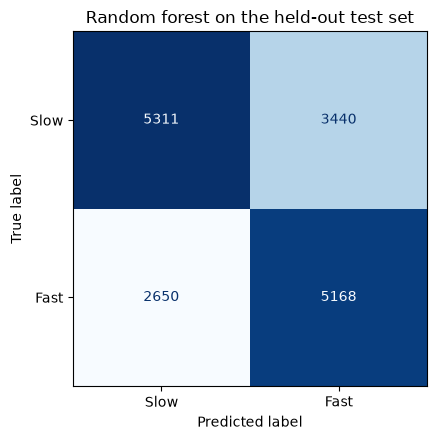

In [17]:
import joblib
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from src.model import validation_scores

selected_name = comparison["ROC-AUC"].idxmax()
fit_X = pd.concat([X["train"], X["validation"]])
fit_y = pd.concat([y["train"], y["validation"]])
final_models = {
    name: clone(models[name]).fit(fit_X, fit_y)
    for name in ("Majority baseline", selected_name)
}
test_scores = pd.DataFrame.from_dict({
    name: validation_scores(model, X["test"], y["test"])
    for name, model in final_models.items()
}, orient="index")
display(test_scores.round(4))

final_model = final_models[selected_name]
counts = confusion_matrix(y["test"], final_model.predict(X["test"]), labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(counts, display_labels=["Slow", "Fast"]).plot(
    ax=ax, colorbar=False, cmap="Blues"
)
ax.set_title(f"{selected_name} on the held-out test set")
fig.tight_layout()
figures = project / "reports" / "figures"
figures.mkdir(parents=True, exist_ok=True)
fig.savefig(figures / "test_confusion_matrix.png", dpi=160)
plt.show()
plt.close(fig)

model_path = project / "models" / "resolution_classifier.joblib"
joblib.dump(final_model, model_path)
reloaded = joblib.load(model_path)
assert (reloaded.predict(X["test"]) == final_model.predict(X["test"])).all()

## Step 10 - Feature importance and SHAP

Explain the probability of slow resolution. SHAP starts with a model baseline and assigns contributions that increase or decrease that probability. Sum the effects of encoded indicators back to their original input field. For global importance, average the absolute grouped contribution across a reproducible sample of 256 held-out tickets.

These are model explanations. Correlated inputs can share credit, and the ranking can vary with the sample. The scores reflect patterns in simulated tickets.

c:\Users\HP\Documents\Customer Support Tickets\it-support-analytics\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


day_of_week      0.073708
category         0.066883
is_weekend       0.030971
hour_created     0.012669
month_created    0.004002
product          0.003393
channel          0.003385
Name: mean_absolute_effect, dtype: float64

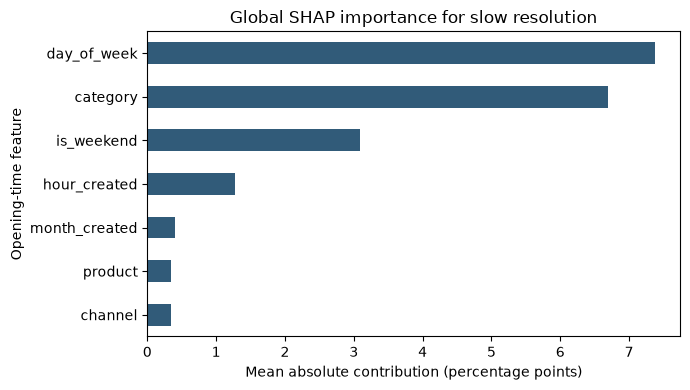

day_of_week      23.501119
is_weekend       17.335099
category          3.355625
channel           0.258967
product           0.194061
hour_created      0.024638
month_created    -0.009588
Name: percentage_points, dtype: float64

Baseline: 52.9% | Predicted slow: 97.6%


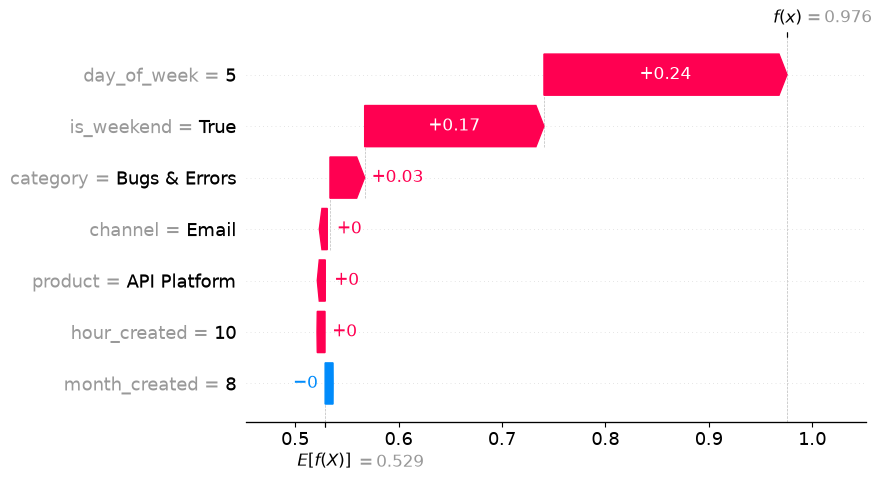

In [18]:
import shap

from src.prediction import explain_slow_resolution

sample = X["test"].sample(n=256, random_state=42)
baseline, contributions = explain_slow_resolution(final_model, sample)
importance = contributions.abs().mean().sort_values()
display(importance.sort_values(ascending=False).rename("mean_absolute_effect"))
fig, ax = plt.subplots(figsize=(7, 4))
importance.mul(100).plot.barh(ax=ax, color="#315b79")
ax.set(title="Global SHAP importance for slow resolution",
       xlabel="Mean absolute contribution (percentage points)", ylabel="Opening-time feature")
fig.tight_layout()
fig.savefig(figures / "shap_feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Choose the sampled ticket with the highest predicted slow-resolution probability.
slow_probability = final_model.predict_proba(sample)[:, list(final_model.classes_).index(0)]
position = int(slow_probability.argmax())
effects = contributions.iloc[position]
display(effects.mul(100).sort_values(key=abs, ascending=False).rename("percentage_points"))
print(f"Baseline: {baseline[position]:.1%} | Predicted slow: {slow_probability[position]:.1%}")
shap.plots.waterfall(
    shap.Explanation(
        values=effects.to_numpy(), base_values=baseline[position],
        feature_names=[f"{name} = {sample.iloc[position][name]}" for name in effects.index],
    ),
    show=False,
)
plt.gcf().savefig(figures / "shap_slow_resolution_example.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

## Export dashboard metrics

In [ ]:
import json

dashboard_metrics = {
    "selected_model": selected_name,
    "test_tickets": len(y["test"]),
    "validation": comparison.drop(columns="Fit seconds").to_dict(orient="index"),
    "test": test_scores.to_dict(orient="index"),
}
(project / "models" / "dashboard_metrics.json").write_text(
    json.dumps(dashboard_metrics, indent=2), encoding="utf-8"
)